# ПР №6 — Классификация текстов, уровень B

Используется `reviews.csv` — **синтетический учебный корпус** коротких отзывов на русском; реальный корпус преподавателя не предоставлен. Некоторые отзывы намеренно противоречивы или шумно размечены, что помогает изучать ошибки модели.

In [1]:
from pathlib import Path
import re, numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,accuracy_score,f1_score,confusion_matrix,ConfusionMatrixDisplay
FIG=Path('../figures');FIG.mkdir(exist_ok=True)
df=pd.read_csv('../data/reviews.csv')
print('Документы:',len(df),'Классы:',df.sentiment.value_counts().to_dict())
display(df.head())

Документы: 420 Классы: {0: 210, 1: 210}


,text,sentiment
0,"Купил для семьи свитер. доставка долгая, слома...",0
1,"Сегодня купил свитер. качество ужасное, цена з...",0
2,"Проверил дома товар. качество хорошее, звук чи...",1
3,"часы: всё плохо, но покупкой доволен. В целом ...",1
4,"Долго выбирал: монитор. покупкой недоволен, ка...",0


## Очистка: регистр, пунктуация, цифры, стоп-слова

**Отрицания `не` и `нет` оставлены**, поскольку их удаление меняет смысл фраз «не понравилось», «нет проблем». Лемматизацию не добавляем: на коротких учебных текстах проверяем базовое решение без внешнего словаря.

In [2]:
STOP={'и','а','но','же','это','в','во','на','к','от','до','за','у','с','со','по','для','что','как','так','был','была','были','есть','очень','всё','все','мне','мой','моя','пару','день','после','через','еще','ещё'}
def clean_text(s):
    s=re.sub(r'[^а-яё\s]',' ',str(s).lower())
    return ' '.join(w for w in s.split() if len(w)>1 and w not in STOP)
print('До:',df.text.iloc[0]);print('После:',clean_text(df.text.iloc[0]))
Xtr,Xte,ytr,yte=train_test_split(df.text,df.sentiment,test_size=.25,stratify=df.sentiment,random_state=42)

До: Купил для семьи свитер. доставка долгая, сломался быстро. в целом.
После: купил семьи свитер доставка долгая сломался быстро целом


## TF-IDF с ограничением словаря и модель

Вся векторизация обучается только на `train` через `Pipeline`. Задаём `min_df=2`, `max_df=0.95` и биграммы: сочетание «не советую» отличается от «советую».

Размерность TF-IDF train: (315, 454)
Accuracy: 0.943 F1: 0.943
              precision    recall  f1-score   support

           0      0.961     0.925     0.942        53
           1      0.926     0.962     0.943        52

    accuracy                          0.943       105
   macro avg      0.943     0.943     0.943       105
weighted avg      0.944     0.943     0.943       105



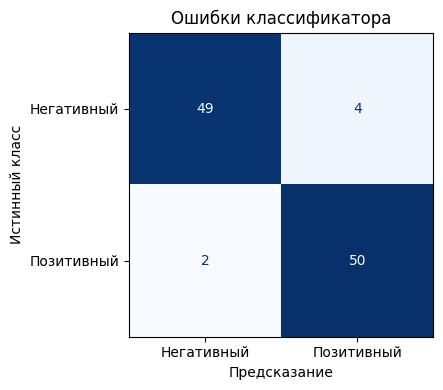

In [3]:
pipeline=Pipeline([('tfidf',TfidfVectorizer(preprocessor=clean_text,lowercase=False,token_pattern=r'(?u)\b\w+\b',ngram_range=(1,2),min_df=2,max_df=.95,max_features=2500)),('model',LogisticRegression(max_iter=2000,random_state=42))])
pipeline.fit(Xtr,ytr)
pred=pipeline.predict(Xte)
vectorizer=pipeline.named_steps['tfidf']
print('Размерность TF-IDF train:',vectorizer.transform(Xtr).shape)
print('Accuracy:',round(accuracy_score(yte,pred),3),'F1:',round(f1_score(yte,pred),3))
print(classification_report(yte,pred,digits=3,zero_division=0))
fig,ax=plt.subplots(figsize=(5,4));ConfusionMatrixDisplay.from_predictions(yte,pred,display_labels=['Негативный','Позитивный'],ax=ax,cmap='Blues',colorbar=False)
ax.set(title='Ошибки классификатора',xlabel='Предсказание',ylabel='Истинный класс')
fig.tight_layout();fig.savefig(FIG/'confusion.png',dpi=125);plt.show()

## Анализ **пяти реальных ошибок** модели

Не будем придумывать примеры заранее. Получим конкретные неправильно классифицированные объекты из отложенной тестовой выборки. Возможные причины: смешанная тональность, шумная метка, отрицания, редкая лексика.

In [4]:
errors=pd.DataFrame({'text':Xte.to_numpy(),'true':yte.to_numpy(),'pred':pred})
errors=errors[errors.true!=errors.pred].copy()
def hypothesis(text):
    s=text.lower()
    if 'но' in s or 'спорное' in s:return 'В одном отзыве есть противоположные оценки / смешанная тональность.'
    if 'не ' in s:return 'Отрицание меняет смысл; возможна неоднозначность сочетания слов.'
    return 'Реальная ошибка: недостающий контекст, шумная метка или редкие слова.'
errors['hypothesis']=errors.text.map(hypothesis)
print('Всего ошибок:',len(errors))
assert len(errors)>=5, 'Для требования 5 ошибок нужен больший или более сложный учебный корпус'
display(errors.head(5).reset_index(drop=True))
Path('../reports').mkdir(exist_ok=True)
errors.head(5).to_csv('../reports/five_errors.csv',index=False)

Всего ошибок: 6


,text,true,pred,hypothesis
0,"чайник: советую купить, в целом.",0,1,"Реальная ошибка: недостающий контекст, шумная ..."
1,"монитор: отличная вещь, но всё плохо. В целом ...",0,1,В одном отзыве есть противоположные оценки / с...
2,"клавиатура: доставка быстрая, но не советую ку...",0,1,В одном отзыве есть противоположные оценки / с...
3,"наушники: всё идеально, упаковка целая.",0,1,В одном отзыве есть противоположные оценки / с...
4,"клавиатура: сломался быстро, упаковка целая.",1,0,"Реальная ошибка: недостающий контекст, шумная ..."


## Итог

TF-IDF описывает слова и пары слов, но плохо понимает контекст, иронию и противоречивые отзывы. На нескольких ошибках видны ограничения мешка слов. Перед обучением на другом корпусе нужно заново проверить стоп-слова и качество разметки; **отрицания нельзя удалять автоматически**.